In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
file_path = "/Users/tomamely/Desktop/Ironhack 2025/amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(file_path)
df.head()
# 

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [42]:
print(df['stars'].value_counts(dropna=False).sort_index())
print(f"Missing values in stars: {df['stars'].isna().sum()}")

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64
Missing values in stars: 0


In [43]:
num_zeros = (df['stars'] == 0).sum()
print(f"Number of zero ratings: {num_zeros}")

Number of zero ratings: 1225641


In [41]:
print(df['stars'].dtype)

float64


In [44]:
df_clean = df[df['stars'] > 0]
print(f"Shape before cleaning: {df.shape}")
print(f"Shape after cleaning: {df_clean.shape}")

Shape before cleaning: (2443651, 9)
Shape after cleaning: (1218010, 9)


In [14]:
category_counts = df['category'].value_counts()
print(category_counts.head(5))

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


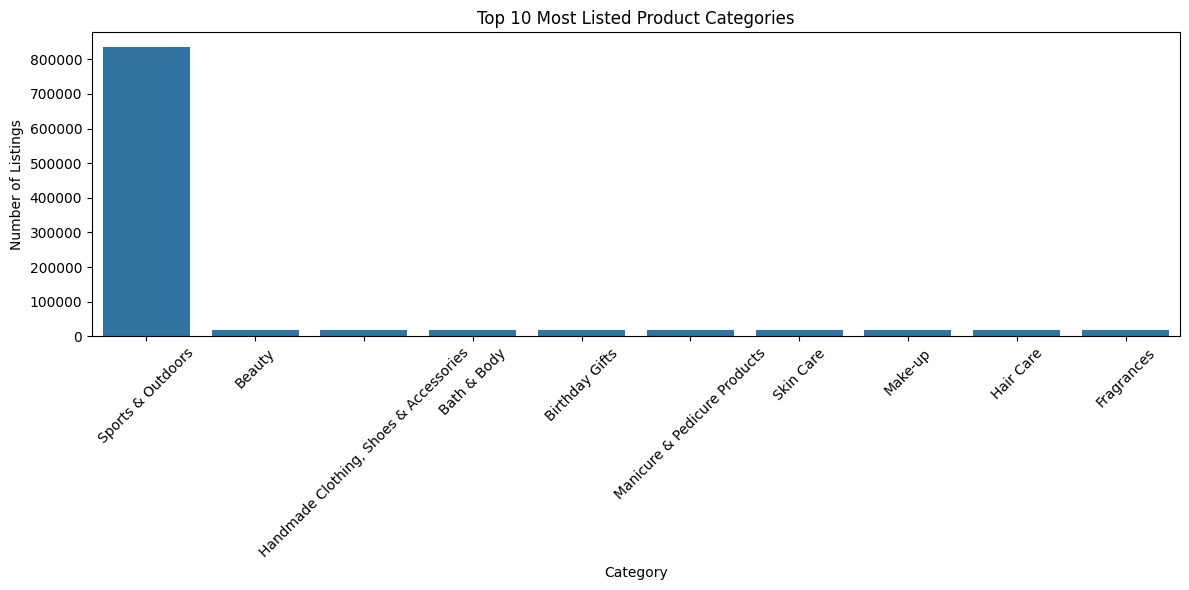

In [15]:
plt.figure(figsize=(12, 6))
sns.barplot(x=category_counts.index[:10], y=category_counts.values[:10])
plt.title("Top 10 Most Listed Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
top_5_categories = df['category'].value_counts().head(5)

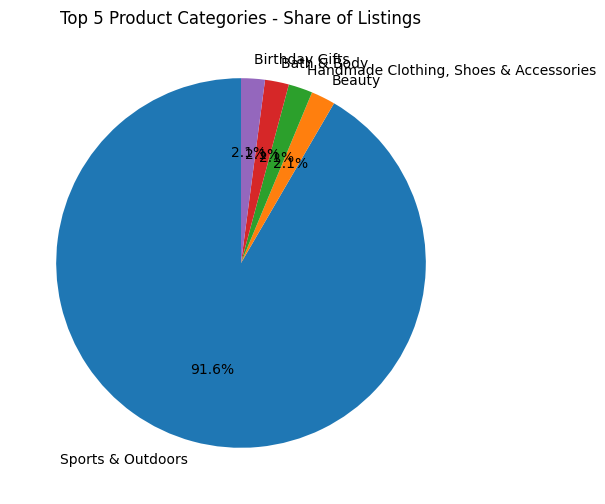

In [19]:

top_5_categories.plot.pie(autopct='%1.1f%%', startangle=90, figsize=(6, 6), legend=False)
plt.title("Top 5 Product Categories - Share of Listings")
plt.ylabel('')  # Убираем подпись оси Y
plt.show()

In [20]:
price_column = 'price'  

mean_price = df[price_column].mean()
median_price = df[price_column].median()
mode_price = df[price_column].mode()[0]  # mode возвращает серию, берём первое значение

print(f"Mean price: {mean_price:.2f}")
print(f"Median price: {median_price:.2f}")
print(f"Mode price: {mode_price:.2f}")

Mean price: 89.24
Median price: 19.09
Mode price: 9.99


In [21]:
variance_price = df[price_column].var()
std_price = df[price_column].std()
price_range = df[price_column].max() - df[price_column].min()
Q1 = df[price_column].quantile(0.25)
Q3 = df[price_column].quantile(0.75)
IQR = Q3 - Q1

print(f"Variance: {variance_price:.2f}")
print(f"Standard deviation: {std_price:.2f}")
print(f"Range: {price_range:.2f}")
print(f"Interquartile Range (IQR): {IQR:.2f}")

Variance: 119445.49
Standard deviation: 345.61
Range: 100000.00
Interquartile Range (IQR): 36.00


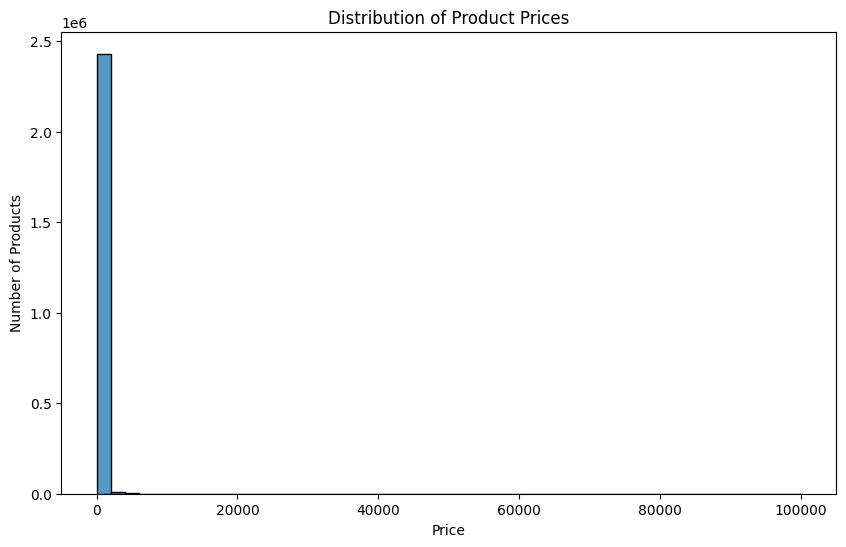

In [22]:
plt.figure(figsize=(10,6))
sns.histplot(df[price_column], bins=50, kde=False)
plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")
plt.show()

<Axes: xlabel='price', ylabel='Count'>

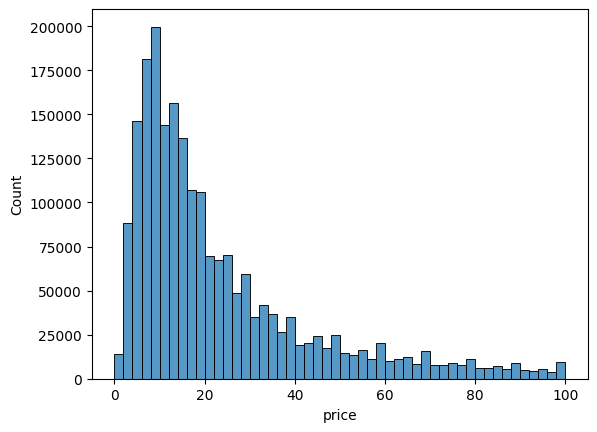

In [24]:
sns.histplot(df[df['price'] < 100]['price'], bins=50)

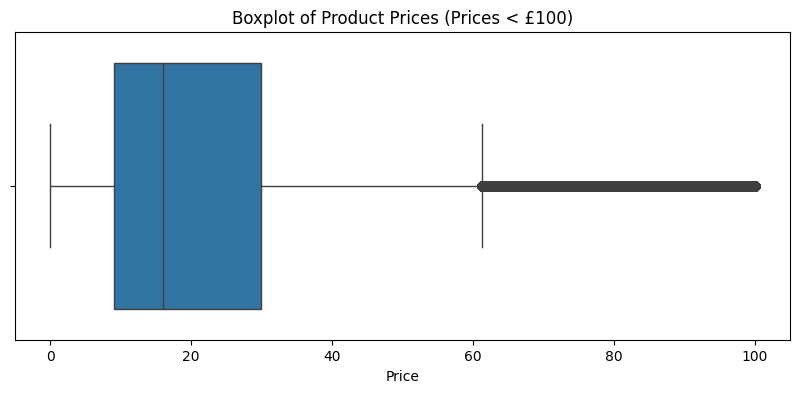

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.boxplot(x=df[df['price'] < 100]['price'])
plt.title("Boxplot of Product Prices (Prices < £100)")
plt.xlabel("Price")
plt.show()

In [46]:
rating_col = 'stars'
mean_rating = df_clean[rating_col].mean()
median_rating = df_clean[rating_col].median()
mode_rating = df_clean[rating_col].mode()[0]

print(f"Mean rating: {mean_rating:.2f}")
print(f"Median rating: {median_rating:.2f}")
print(f"Mode rating: {mode_rating:.2f}")

Mean rating: 4.32
Median rating: 4.40
Mode rating: 4.50


In [47]:
variance_rating = df_clean[rating_col].var()
std_rating = df_clean[rating_col].std()
Q1 = df_clean[rating_col].quantile(0.25)
Q3 = df_clean[rating_col].quantile(0.75)
IQR_rating = Q3 - Q1

print(f"Variance: {variance_rating:.4f}")
print(f"Standard deviation: {std_rating:.4f}")
print(f"Interquartile Range (IQR): {IQR_rating:.4f}")

Variance: 0.3083
Standard deviation: 0.5553
Interquartile Range (IQR): 0.5000


In [48]:
skewness_rating = skew(df_clean[rating_col].dropna())
kurtosis_rating = kurtosis(df_clean[rating_col].dropna())

print(f"Skewness: {skewness_rating:.4f}")
print(f"Kurtosis: {kurtosis_rating:.4f}")

Skewness: -2.3796
Kurtosis: 9.7819


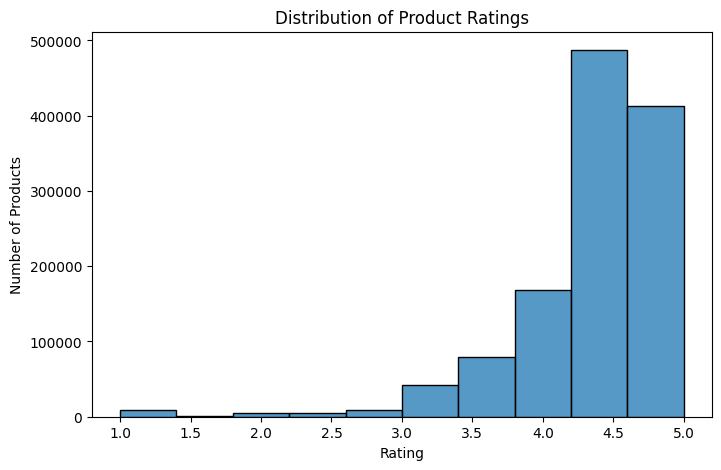

In [49]:
plt.figure(figsize=(8,5))
sns.histplot(df_clean[rating_col].dropna(), bins=10, kde=False)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()